# Picked Architecture (Regularized Network)
A PyTorch network designed for this project: input -> 3 hidden blocks (Linear -> BatchNorm -> activation -> Dropout)
with widths (w, w, w/2) -> output. Batch normalization, dropout and weight decay are added to reduce the
overfitting seen for Concrete with the 4L and 5L networks.

In [1]:
import os
import itertools
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# small networks train faster on a single cpu thread
torch.set_num_threads(1)

# folders for saved figures and tables (used in the report)
FIG_DIR = "figures/Custom"
RESULTS_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.10.0


## Data Loading and Preprocessing

In [2]:
# load the same three datasets used for the 2L network
airfoil = pd.read_csv("../data/airfoil.csv")
auto = pd.read_csv("../data/auto_mpg.csv")
concrete = pd.read_csv("../data/concrete.csv")

# dataset name -> (dataframe, target column)
datasets = {
    "Airfoil": (airfoil, "scaled_sound_pressure_db"),
    "Auto MPG": (auto, "mpg"),
    "Concrete": (concrete, "compressive_strength_mpa")
}

for name, (df, target) in datasets.items():
    missing = df.isnull().sum().sum()
    print(f"{name}: shape={df.shape}, target={target}, missing values={missing}")

Airfoil: shape=(1503, 6), target=scaled_sound_pressure_db, missing values=0
Auto MPG: shape=(392, 8), target=mpg, missing values=0
Concrete: shape=(1030, 9), target=compressive_strength_mpa, missing values=0


In [3]:
# separate predictors and target, then split into 80% training and 20% validation
# (same random_state as the 2L notebook so both models see identical splits)
splits = {}

for name, (df, target) in datasets.items():
    X = df.drop(columns=[target])
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )
    splits[name] = (X_train, X_test, y_train, y_test)
    print(f"{name}: train={X_train.shape}, validation={X_test.shape}")

Airfoil: train=(1202, 5), validation=(301, 5)
Auto MPG: train=(313, 7), validation=(79, 7)
Concrete: train=(824, 8), validation=(206, 8)


## Neural Network Setup

In [4]:
# standardize predictors and target using training data only, then convert to tensors
# the target is standardized because the hidden layers train poorly on raw targets
# such as airfoil (~125 dB); predictions are converted back to the original scale for QoF
def prepare_data(X_train, X_test, y_train, y_test):
    x_scaler = StandardScaler()
    X_train = x_scaler.fit_transform(X_train)
    X_test = x_scaler.transform(X_test)

    y_scaler = StandardScaler()
    y_train_s = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))
    y_test_s = y_scaler.transform(y_test.to_numpy().reshape(-1, 1))

    tensors = {
        "X_train": torch.tensor(X_train, dtype=torch.float32),
        "X_test": torch.tensor(X_test, dtype=torch.float32),
        "y_train_s": torch.tensor(y_train_s, dtype=torch.float32),  # scaled targets for training
        "y_test_s": torch.tensor(y_test_s, dtype=torch.float32),
        "y_train": y_train.to_numpy().reshape(-1, 1),               # original-scale targets for QoF
        "y_test": y_test.to_numpy().reshape(-1, 1)
    }
    return tensors, y_scaler

data = {}
for name, (X_train, X_test, y_train, y_test) in splits.items():
    data[name] = prepare_data(X_train, X_test, y_train, y_test)
    t = data[name][0]
    print(f"{name} Tensors: X_train={tuple(t['X_train'].shape)}, y_train={tuple(t['y_train_s'].shape)}")

Airfoil Tensors: X_train=(1202, 5), y_train=(1202, 1)
Auto MPG Tensors: X_train=(313, 7), y_train=(313, 1)
Concrete Tensors: X_train=(824, 8), y_train=(824, 1)


In [5]:
# one hidden block: linear -> batch normalization -> activation -> dropout
def hidden_block(n_in, n_out, activation, dropout):
    return nn.Sequential(
        nn.Linear(n_in, n_out),
        nn.BatchNorm1d(n_out),   # normalizes the layer inputs for each mini-batch
        activation(),
        nn.Dropout(dropout)      # randomly zeroes nodes during training (regularization)
    )

# picked architecture: input -> block(w) -> block(w) -> block(w/2) -> output
class CustomNet(nn.Module):
    def __init__(self, input_size, width, activation, dropout):
        super().__init__()
        self.block1 = hidden_block(input_size, width, activation, dropout)
        self.block2 = hidden_block(width, width, activation, dropout)
        self.block3 = hidden_block(width, width // 2, activation, dropout)
        self.output = nn.Linear(width // 2, 1)   # identity output for regression

    def forward(self, x):
        return self.output(self.block3(self.block2(self.block1(x))))

# example architecture
print(CustomNet(5, 64, nn.ReLU, 0.1))

CustomNet(
  (block1): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (block3): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (output): Linear(in_features=32, out_features=1, bias=True)
)


## Hyperparameter Tuning

In [6]:
# hyperparameter search space
widths = [64, 128]                                  # nodes in the first two hidden blocks (third has width / 2)
activations = {"ReLU": nn.ReLU, "SiLU": nn.SiLU}
dropouts = [0.0, 0.1, 0.2]
weight_decays = [0.0, 1e-4, 1e-3]                   # L2 penalty on the weights (Adam weight_decay)
batch_sizes = [16, 32]
learning_rates = [0.001, 0.005]
max_epochs = 300
patience = 20

n_configs = (len(widths) * len(activations) * len(dropouts) * len(weight_decays)
             * len(batch_sizes) * len(learning_rates))
print("Configurations per dataset:", n_configs)

Configurations per dataset: 144


In [7]:
# train one configuration with early stopping and return its loss history
def train_with_early_stopping(X_train, y_train, X_val, y_val, width, act, dropout, wd, batch_size, lr):
    torch.manual_seed(42)
    model = CustomNet(X_train.shape[1], width, activations[act], dropout)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    # drop_last avoids a final mini-batch of size 1, which batch normalization cannot handle
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True, drop_last=True)

    train_losses, val_losses = [], []
    best_val_mse = float("inf")
    best_epoch = 0
    wait = 0

    for epoch in range(max_epochs):
        model.train()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

        # training and validation mse (scaled target)
        model.eval()
        with torch.no_grad():
            train_mse = criterion(model(X_train), y_train).item()
            val_mse = criterion(model(X_val), y_val).item()
        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # early stopping on validation mse
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break

    return best_val_mse, best_epoch, train_losses, val_losses

In [8]:
# tune width, activation function, dropout, weight decay, batch size and learning rate
# using an inner 80/20 split of the training data (the 20% validation set is never used here)
def hyperparameter_tuning(X, y, name):

    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

    # standardize predictors and target using only the tuning-training data
    x_scaler = StandardScaler()
    X_train = torch.tensor(x_scaler.fit_transform(X_train), dtype=torch.float32)
    X_val = torch.tensor(x_scaler.transform(X_val), dtype=torch.float32)
    y_scaler = StandardScaler()
    y_train = torch.tensor(y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)), dtype=torch.float32)
    y_val = torch.tensor(y_scaler.transform(y_val.to_numpy().reshape(-1, 1)), dtype=torch.float32)
    y_var = y_scaler.scale_[0] ** 2   # converts scaled mse back to original units

    results = []
    best = None
    start = time.time()

    for width, act, dropout, wd, batch_size, lr in itertools.product(
            widths, activations, dropouts, weight_decays, batch_sizes, learning_rates):
        val_mse, best_epoch, tr_hist, va_hist = train_with_early_stopping(
            X_train, y_train, X_val, y_val, width, act, dropout, wd, batch_size, lr
        )
        row = {
            "width": width,
            "activation": act,
            "dropout": dropout,
            "weight_decay": wd,
            "batch_size": batch_size,
            "learning_rate": lr,
            "val_mse": val_mse * y_var,   # original units
            "epochs": len(tr_hist),
            "best_epoch": best_epoch
        }
        results.append(row)

        if best is None or row["val_mse"] < best[0]["val_mse"]:
            best = (row, {"train": [v * y_var for v in tr_hist],
                          "val": [v * y_var for v in va_hist]})

    results = pd.DataFrame(results).sort_values("val_mse").reset_index(drop=True)
    print(f"{name}: tested {len(results)} configurations in {time.time() - start:.0f}s")
    print("Best Hyperparameters:", best[0])
    return best[0], results, best[1]

In [9]:
# run hyperparameter tuning on the training portion of each dataset
best_params, tuning_results, histories = {}, {}, {}

for name, (X_train, X_test, y_train, y_test) in splits.items():
    print(f"\nTuning {name}...", flush=True)
    best_params[name], tuning_results[name], histories[name] = hyperparameter_tuning(X_train, y_train, name)
    tuning_results[name].to_csv(f"{RESULTS_DIR}/Custom_tuning_{name.lower().replace(' ', '_')}.csv", index=False)


Tuning Airfoil...


Airfoil: tested 144 configurations in 975s
Best Hyperparameters: {'width': 64, 'activation': 'ReLU', 'dropout': 0.0, 'weight_decay': 0.0001, 'batch_size': 32, 'learning_rate': 0.005, 'val_mse': np.float64(4.854495268172579), 'epochs': 95, 'best_epoch': 75}

Tuning Auto MPG...


Auto MPG: tested 144 configurations in 74s
Best Hyperparameters: {'width': 64, 'activation': 'SiLU', 'dropout': 0.0, 'weight_decay': 0.0001, 'batch_size': 16, 'learning_rate': 0.001, 'val_mse': np.float64(5.63576691398), 'epochs': 31, 'best_epoch': 11}

Tuning Concrete...


Concrete: tested 144 configurations in 356s
Best Hyperparameters: {'width': 128, 'activation': 'ReLU', 'dropout': 0.0, 'weight_decay': 0.001, 'batch_size': 32, 'learning_rate': 0.001, 'val_mse': np.float64(19.21732331710611), 'epochs': 111, 'best_epoch': 91}


In [10]:
# top 5 configurations for each dataset
for name, results in tuning_results.items():
    print(f"\n{name} - Top 5 Configurations")
    print(results.head(5).round(4).to_string(index=False))


Airfoil - Top 5 Configurations
 width activation  dropout  weight_decay  batch_size  learning_rate  val_mse  epochs  best_epoch
    64       ReLU      0.0        0.0001          32          0.005   4.8545      95          75
   128       ReLU      0.0        0.0001          32          0.001   5.2461      91          71
   128       ReLU      0.0        0.0000          32          0.001   5.2953      91          71
    64       ReLU      0.0        0.0000          32          0.001   5.2957     170         150
   128       ReLU      0.0        0.0010          32          0.001   5.3977      91          71

Auto MPG - Top 5 Configurations
 width activation  dropout  weight_decay  batch_size  learning_rate  val_mse  epochs  best_epoch
    64       SiLU      0.0        0.0001          16          0.001   5.6358      31          11
    64       SiLU      0.0        0.0010          16          0.001   5.6397      31          11
    64       SiLU      0.0        0.0000          16          

In [11]:
# summary of selected hyperparameters
best_df = pd.DataFrame([
    {"Dataset": name,
     "Hidden Nodes": f"({p['width']}, {p['width']}, {p['width'] // 2})",
     "Activation": p["activation"],
     "Dropout": p["dropout"],
     "Weight Decay": p["weight_decay"],
     "Learning Rate": p["learning_rate"],
     "Batch Size": p["batch_size"],
     "Validation MSE": p["val_mse"],
     "Epochs": p["epochs"],
     "Best Epoch": p["best_epoch"]}
    for name, p in best_params.items()
])
best_df.to_csv(f"{RESULTS_DIR}/Custom_best_hyperparameters.csv", index=False)
print("Picked Architecture - Hyperparameter Tuning Results")
print(best_df.round(4).to_string(index=False))

Picked Architecture - Hyperparameter Tuning Results
 Dataset   Hidden Nodes Activation  Dropout  Weight Decay  Learning Rate  Batch Size  Validation MSE  Epochs  Best Epoch
 Airfoil   (64, 64, 32)       ReLU      0.0        0.0001          0.005          32          4.8545      95          75
Auto MPG   (64, 64, 32)       SiLU      0.0        0.0001          0.001          16          5.6358      31          11
Concrete (128, 128, 64)       ReLU      0.0        0.0010          0.001          32         19.2173     111          91


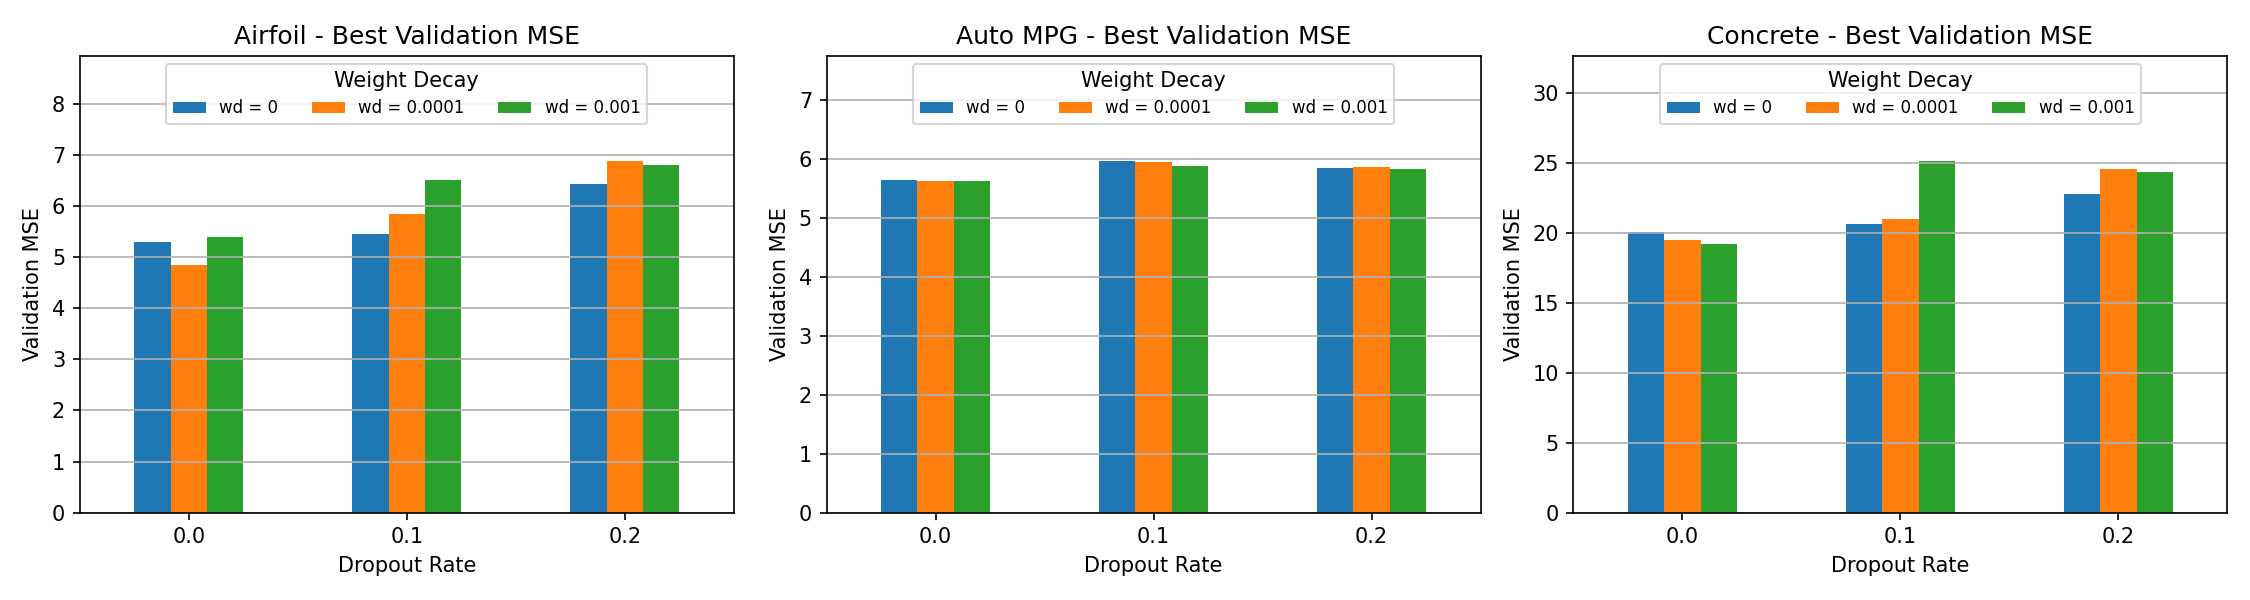

In [12]:
# sensitivity: best tuning validation mse for each dropout rate and weight decay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, results) in zip(axes, tuning_results.items()):
    pivot = results.groupby(["dropout", "weight_decay"])["val_mse"].min().unstack("weight_decay")
    pivot.columns = [f"wd = {w:g}" for w in pivot.columns]
    pivot.plot(kind="bar", ax=ax, rot=0)
    ax.set_ylim(0, pivot.max().max() * 1.3)   # leave room above the bars for the legend
    ax.legend(title="Weight Decay", loc="upper center", ncol=3, fontsize=8)
    ax.set_title(f"{name} - Best Validation MSE")
    ax.set_xlabel("Dropout Rate")
    ax.set_ylabel("Validation MSE")
    ax.grid(True, axis="y")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/tuning_sensitivity.png", dpi=150)
plt.show()

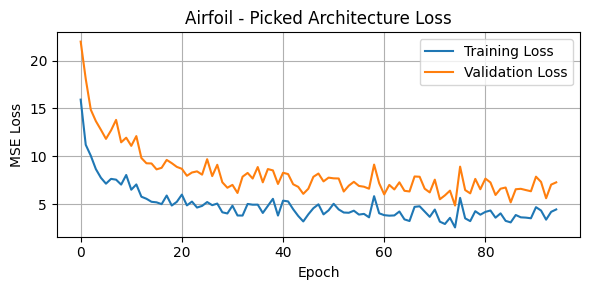

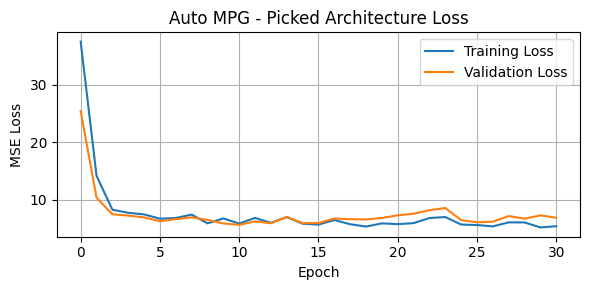

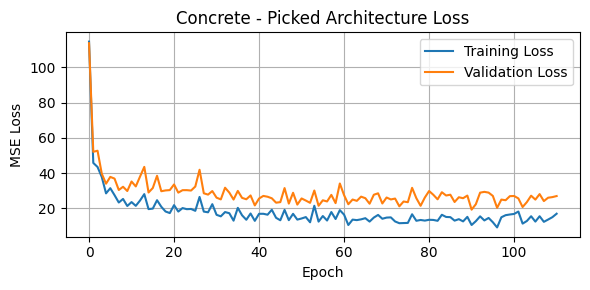

In [13]:
# plot training and validation loss curves for the best configuration
def plot_loss(history, dataset_name):
    plt.figure(figsize=(6, 3))
    plt.plot(history["train"], label="Training Loss")
    plt.plot(history["val"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"{dataset_name} - Picked Architecture Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_loss.png", dpi=150)
    plt.show()

for name, history in histories.items():
    plot_loss(history, name)

## Model Training

In [14]:
# train the final network on the full training set using the best hyperparameters
def train_final_model(X_train, y_train, params, seed=42):
    torch.manual_seed(seed)
    model = CustomNet(X_train.shape[1], params["width"], activations[params["activation"]], params["dropout"])

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=params["learning_rate"], weight_decay=params["weight_decay"])
    loader = DataLoader(
        TensorDataset(X_train, y_train), batch_size=params["batch_size"], shuffle=True, drop_last=True
    )

    # train for the number of epochs selected by early stopping during tuning
    model.train()
    for epoch in range(params["best_epoch"]):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

    return model

models = {}
for name, (t, y_scaler) in data.items():
    models[name] = train_final_model(t["X_train"], t["y_train_s"], best_params[name])
    print(f"{name}:", models[name])

Airfoil: CustomNet(
  (block1): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block3): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (output): Linear(in_features=32, out_features=1, bias=True)
)


Auto MPG: CustomNet(
  (block1): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block3): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (output): Linear(in_features=32, out_features=1, bias=True)
)


Concrete: CustomNet(
  (block1): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (block3): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (output): Linear(in_features=64, out_features=1, bias=True)
)


## Model Evaluation (QoF)

In [15]:
# predictions on the original target scale
def predict(model, X, y_scaler):
    model.eval()
    with torch.no_grad():
        predictions = model(X).numpy()
    return y_scaler.inverse_transform(predictions)

# calculate r², mse, and rmse for neural network predictions
def evaluate_model(model, X, y, y_scaler):
    predictions = predict(model, X, y_scaler)
    r2 = r2_score(y, predictions)
    mse = mean_squared_error(y, predictions)
    rmse = np.sqrt(mse)
    return r2, mse, rmse

In [16]:
# compare in-sample (training) and validation QoF across all three datasets
qof_results = []

for name, (t, y_scaler) in data.items():
    train_r2, train_mse, train_rmse = evaluate_model(models[name], t["X_train"], t["y_train"], y_scaler)
    val_r2, val_mse, val_rmse = evaluate_model(models[name], t["X_test"], t["y_test"], y_scaler)

    qof_results.append({
        "Dataset": name,
        "Train R²": train_r2,
        "Validation R²": val_r2,
        "Train MSE": train_mse,
        "Validation MSE": val_mse,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

qof_df = pd.DataFrame(qof_results)
qof_df.to_csv(f"{RESULTS_DIR}/Custom_qof.csv", index=False)
print("Picked Architecture - Quality of Fit")
print(qof_df.round(4).to_string(index=False))

Picked Architecture - Quality of Fit
 Dataset  Train R²  Validation R²  Train MSE  Validation MSE  Train RMSE  Validation RMSE
 Airfoil    0.8898         0.8688     5.1715          6.5710      2.2741           2.5634
Auto MPG    0.8923         0.8717     6.7944          6.5488      2.6066           2.5591
Concrete    0.9466         0.8677    15.1638         34.0992      3.8941           5.8394


In [17]:
# compare with the 4L network (same train/validation split), including the training-validation gap
qof_4l = pd.read_csv(f"{RESULTS_DIR}/4L_qof.csv")
comparison = qof_4l[["Dataset", "Train R²", "Validation R²"]].rename(
    columns={"Train R²": "4L Train R²", "Validation R²": "4L Validation R²"}
).merge(
    qof_df[["Dataset", "Train R²", "Validation R²"]].rename(
        columns={"Train R²": "Picked Train R²", "Validation R²": "Picked Validation R²"}
    ),
    on="Dataset"
)
comparison["4L Gap"] = comparison["4L Train R²"] - comparison["4L Validation R²"]
comparison["Picked Gap"] = comparison["Picked Train R²"] - comparison["Picked Validation R²"]
print("4L vs. Picked Architecture")
print(comparison.round(4).to_string(index=False))

4L vs. Picked Architecture
 Dataset  4L Train R²  4L Validation R²  Picked Train R²  Picked Validation R²  4L Gap  Picked Gap
 Airfoil       0.9720            0.9643           0.8898                0.8688  0.0077      0.0209
Auto MPG       0.8581            0.8317           0.8923                0.8717  0.0264      0.0206
Concrete       0.9623            0.8691           0.9466                0.8677  0.0932      0.0790


## Visualizations

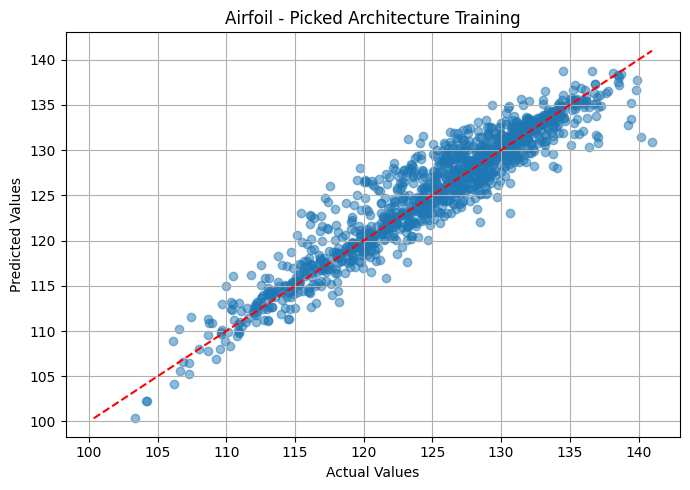

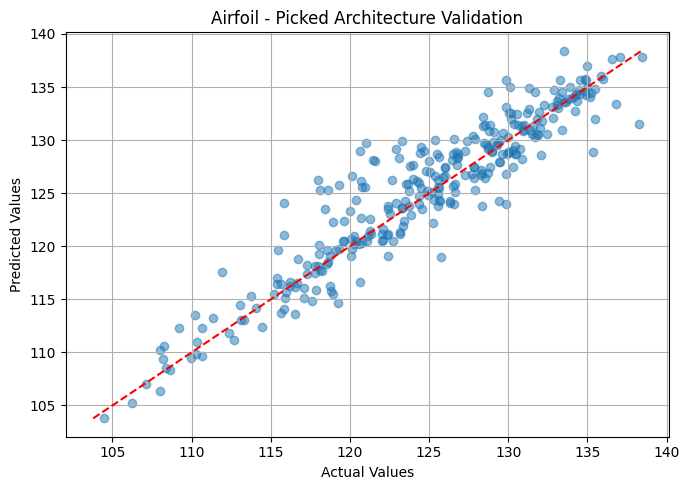

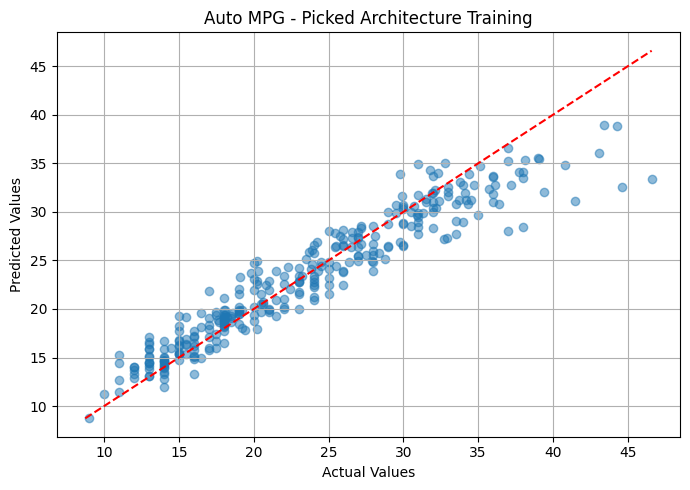

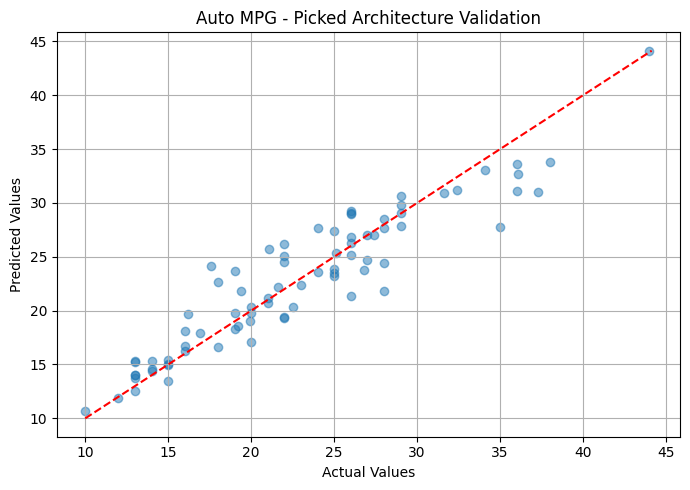

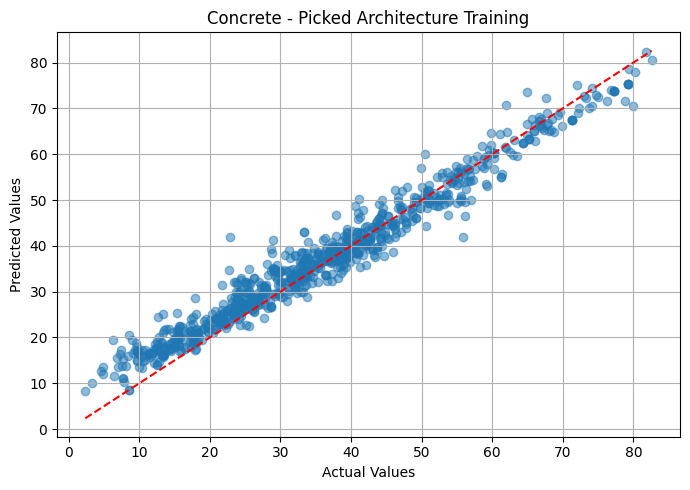

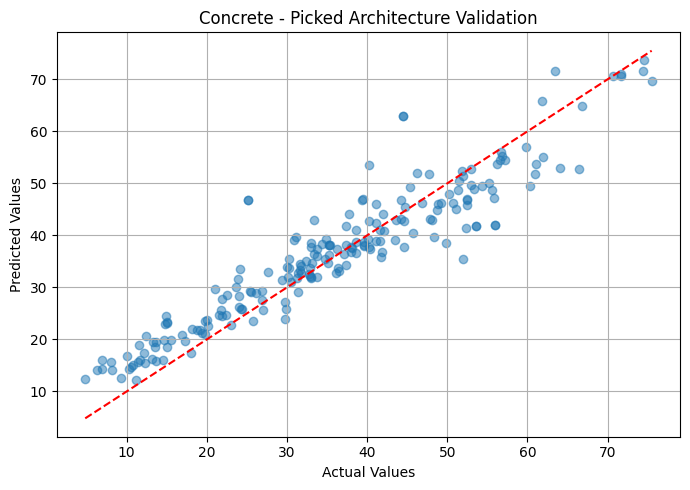

In [18]:
# plot actual vs. predicted values
def plot_predictions(model, X, y, y_scaler, dataset_name, split_name):
    predictions = predict(model, X, y_scaler).flatten()
    actual = y.flatten()

    plt.figure(figsize=(7, 5))
    plt.scatter(actual, predictions, alpha=0.5)

    # perfect prediction line
    min_val = min(actual.min(), predictions.min())
    max_val = max(actual.max(), predictions.max())
    plt.plot([min_val, max_val], [min_val, max_val], "r--")

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{dataset_name} - Picked Architecture {split_name}")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_{split_name.lower()}_pred.png", dpi=150)
    plt.show()

for name, (t, y_scaler) in data.items():
    plot_predictions(models[name], t["X_train"], t["y_train"], y_scaler, name, "Training")
    plot_predictions(models[name], t["X_test"], t["y_test"], y_scaler, name, "Validation")

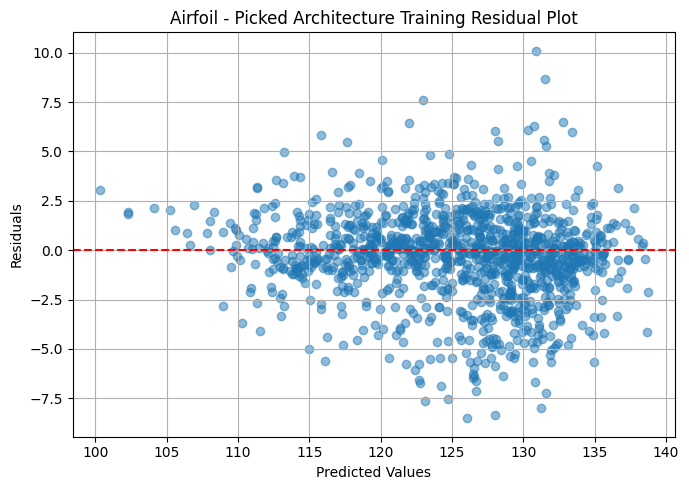

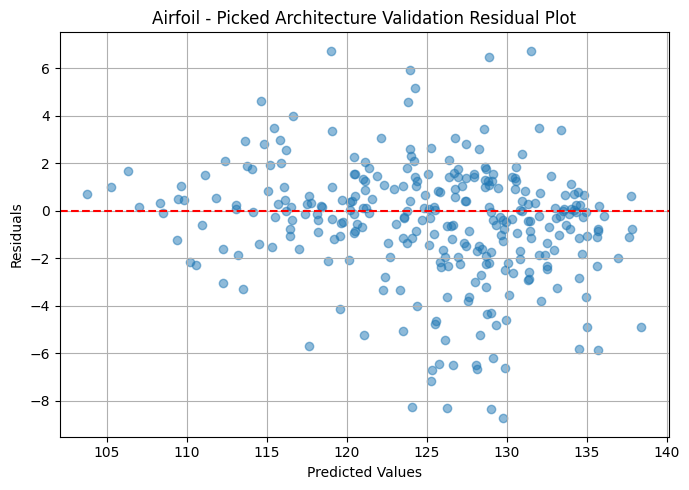

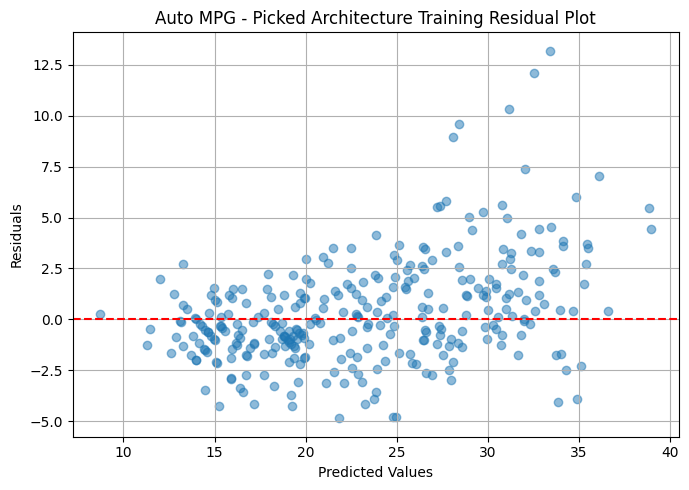

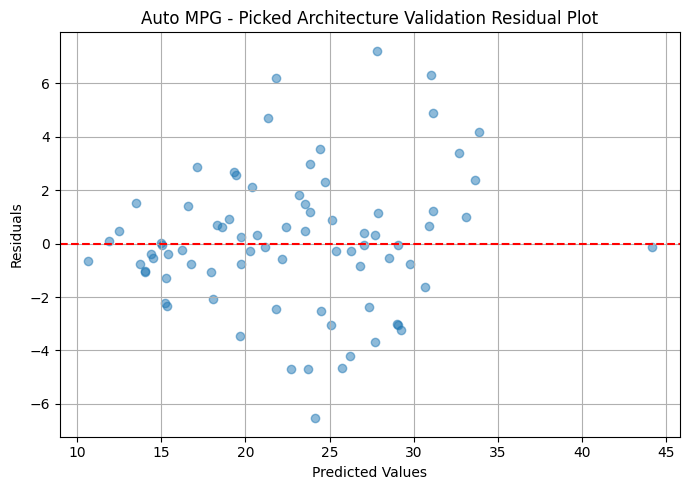

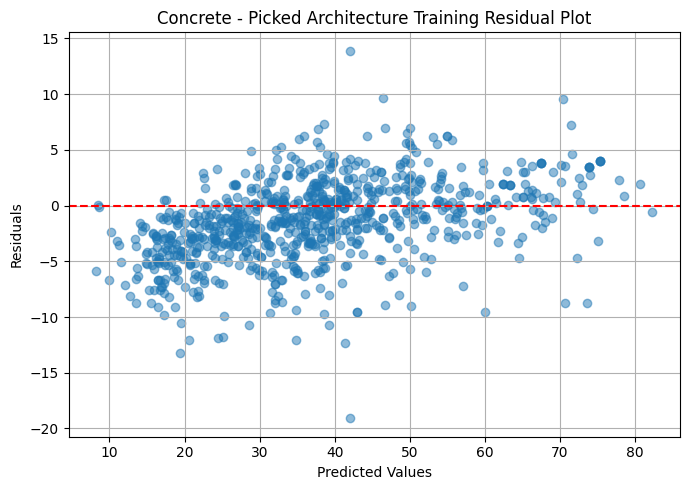

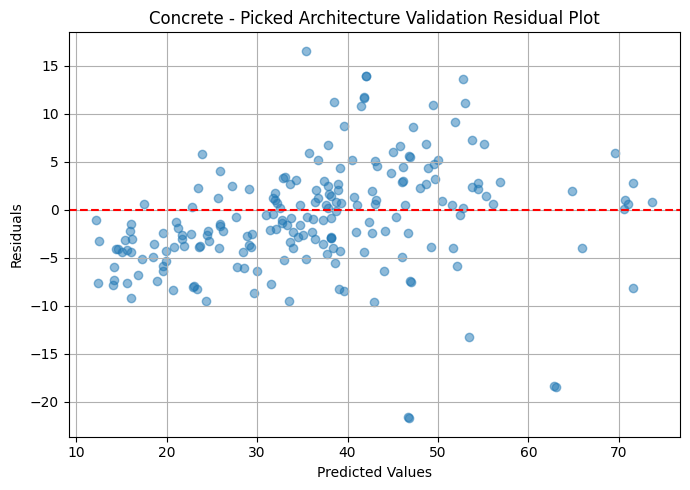

In [19]:
# plot residuals against predicted values
def plot_residuals(model, X, y, y_scaler, dataset_name, split_name):
    predictions = predict(model, X, y_scaler).flatten()
    residuals = y.flatten() - predictions

    plt.figure(figsize=(7, 5))
    plt.scatter(predictions, residuals, alpha=0.5)
    plt.axhline(y=0, color="red", linestyle="--")

    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title(f"{dataset_name} - Picked Architecture {split_name} Residual Plot")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_{split_name.lower()}_resid.png", dpi=150)
    plt.show()

for name, (t, y_scaler) in data.items():
    plot_residuals(models[name], t["X_train"], t["y_train"], y_scaler, name, "Training")
    plot_residuals(models[name], t["X_test"], t["y_test"], y_scaler, name, "Validation")

## Seed Stability

In [20]:
# retrain the final models with five seeds to check how much validation r2 depends on initialization
seed_rows = []
for name, (t, y_scaler) in data.items():
    r2s = []
    for seed in range(5):
        m = train_final_model(t["X_train"], t["y_train_s"], best_params[name], seed=seed)
        r2s.append(evaluate_model(m, t["X_test"], t["y_test"], y_scaler)[0])
    seed_rows.append({"Dataset": name, "Mean Validation R²": np.mean(r2s), "SD": np.std(r2s),
                      "Min": min(r2s), "Max": max(r2s)})

seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv(f"{RESULTS_DIR}/Custom_seed_stability.csv", index=False)
print(seed_df.round(4).to_string(index=False))

 Dataset  Mean Validation R²     SD    Min    Max
 Airfoil              0.8886 0.0220 0.8522 0.9163
Auto MPG              0.8737 0.0082 0.8584 0.8821
Concrete              0.8757 0.0026 0.8732 0.8806
